In [ ]:
import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Đánh giá
from sklearn.metrics import (
    classification_report, 
    f1_score, 
    recall_score, 
    precision_score, 
    roc_auc_score, 
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

# Đường dẫn đến thư mục chứa dữ liệu đã xử lý
DATA_PATH = r"D:/AI66A_group_10_Topic_7/src/data/processed"

In [24]:
def load_data(path):
    X_train = joblib.load(os.path.join(path, 'X_train.pkl'))
    y_train = joblib.load(os.path.join(path, 'y_train.pkl'))
    X_test = joblib.load(os.path.join(path, 'X_test.pkl'))
    y_test = joblib.load(os.path.join(path, 'y_test.pkl'))
    X_val = joblib.load(os.path.join(path, 'X_val.pkl'))
    y_val = joblib.load(os.path.join(path, 'y_val.pkl'))
    feature_cols = joblib.load(os.path.join(path, 'feature_cols.pkl'))
    return X_train, y_train, X_test, y_test, X_val, y_val, feature_cols

X_train, y_train, X_test, y_test, X_val, y_val, feature_cols = load_data(DATA_PATH)
print(f" Train set: {X_train.shape}")
print(f" Test set: {X_test.shape}")
print(f" Validation set: {X_val.shape}")


 Train set: (416250, 28)
 Test set: (89197, 28)
 Validation set: (89197, 28)


## 1. Huấn luyện Balanced Random Forest Classifier

`BalancedRandomForestClassifier` từ thư viện `imbalanced-learn` xử lý mất cân bằng lớp bằng cách **random under-sampling** trên lớp đa số trong mỗi bootstrap sample khi xây dựng từng cây quyết định — không cần dùng SMOTE.

In [25]:
from imblearn.ensemble import BalancedRandomForestClassifier
# Khởi tạo model
brf_model = BalancedRandomForestClassifier(
    n_estimators=1000,          
    max_depth=6,           
    min_samples_split=2,       
    min_samples_leaf=1,        
    max_features='sqrt',       
    sampling_strategy='auto',  
    replacement=False,         
    bootstrap=True,            
    random_state=42,
    n_jobs=-1,
                     
)

brf_model.fit(X_train, y_train)


BalancedRandomForestClassifier(bootstrap=True, max_depth=6, n_estimators=1000,
                               n_jobs=-1, random_state=42, replacement=False,
                               sampling_strategy='auto')

## 2. Baseline Evaluation

In [26]:
def calculate_metrics(y_true, y_pred, y_prob, label=""):
    metrics = {
        "F1": f1_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }
    if label:
        print(f"\n=== {label} ===")
        for k, v in metrics.items():
            print(f"  {k}: {v:.4f}")
    return metrics

# --- Baseline: đánh giá trên val set ---
brf_val_preds   = brf_model.predict(X_val)
brf_val_probs   = brf_model.predict_proba(X_val)[:, 1]


brf_baseline_val = calculate_metrics(y_val, brf_val_preds, brf_val_probs, "Balanced Random Forest Baseline – Val")


# --- Baseline: đánh giá trên test set ---
brf_test_preds  = brf_model.predict(X_test)
brf_test_probs  = brf_model.predict_proba(X_test)[:, 1]


brf_baseline_test = calculate_metrics(y_test, brf_test_preds, brf_test_probs, "Balanced Random Forest Baseline – Test")
# xgb_baseline_test = calculate_metrics(y_test, xgb_test_preds, xgb_test_probs, "XGBoost Baseline – Test")

# Bảng tóm tắt baseline
baseline_df = pd.DataFrame(
    [brf_baseline_val, brf_baseline_test],
    index=["Balanced Random Forest - Val", "Balanced Random Forest - Test"]
)
print("\nBaseline table:")
display(baseline_df.round(4))


=== Balanced Random Forest Baseline – Val ===
  F1: 0.5807
  Recall: 0.9854
  Precision: 0.4116
  ROC-AUC: 0.9979
  PR-AUC: 0.8580

=== Balanced Random Forest Baseline – Test ===
  F1: 0.5807
  Recall: 0.9854
  Precision: 0.4116
  ROC-AUC: 0.9979
  PR-AUC: 0.8580

Baseline table:


,F1,Recall,Precision,ROC-AUC,PR-AUC
Balanced Random Forest - Val,0.5807,0.9854,0.4116,0.9979,0.858
Balanced Random Forest - Test,0.5807,0.9854,0.4116,0.9979,0.858


## 3.Optuna - Tối ưu Hyperparameters  

In [27]:

def brf_objective(trial):
    params = {
        "n_estimators":     trial.suggest_int("n_estimators", 200, 2000),
        "max_depth":        trial.suggest_int("max_depth", 3, 12),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "min_samples_split":trial.suggest_int("min_samples_split", 2, 10),
        "max_features":     trial.suggest_categorical("max_features", ["sqrt", "log2"]),
        "random_state": 42,
        "n_jobs": -1,
        
    }
    model = BalancedRandomForestClassifier(**params)
    model.fit(X_train, y_train)
    probs = model.predict_proba(X_val)[:, 1]
    return average_precision_score(y_val, probs)

brf_study = optuna.create_study(direction="maximize", study_name="BalancedRandomForest-PRAUC")
brf_study.optimize(brf_objective, n_trials=50, show_progress_bar=True)

print(f"\nBalancedRandomForest best PR-AUC (val): {brf_study.best_value:.4f}")
print("Best params:", brf_study.best_params)

  0%|          | 0/50 [00:00<?, ?it/s]


BalancedRandomForest best PR-AUC (val): 0.8910
Best params: {'n_estimators': 1279, 'max_depth': 12, 'min_samples_leaf': 8, 'min_samples_split': 8, 'max_features': 'sqrt'}


## 4. Train lại với best params từ Optuna

In [29]:
# --- Retrain BalancedRandomForest ---
brf_best = BalancedRandomForestClassifier(
    **brf_study.best_params,
    random_state=42,
    n_jobs=-1,
    bootstrap=True,

)
brf_best.fit(X_train, y_train)
print("BalancedRandomForest retrained with best params.")



BalancedRandomForest retrained with best params.


## 5. Đánh giá sau Optuna – So sánh trước/sau trên Val Set

In [30]:
# Đánh giá trên val set sau Optuna
brf_opt_val_preds = brf_best.predict(X_val)
brf_opt_val_probs = brf_best.predict_proba(X_val)[:, 1]


brf_opt_val = calculate_metrics(y_val, brf_opt_val_preds, brf_opt_val_probs, "BalancedRandomForest Optuna – Val")

# Bảng so sánh trước / sau Optuna trên Val Set
val_comparison = pd.DataFrame(
    [brf_baseline_val, brf_opt_val],
    index=["BalancedRandomForest - Baseline", "BalancedRandomForest - Optuna"]
)
print("\n Baseline vs Optuna (Val Set):")
display(val_comparison.round(4))

# Cải thiện PR-AUC
brf_gain = brf_opt_val["PR-AUC"] - brf_baseline_val["PR-AUC"]
print(f"\nBalancedRandomForest PR-AUC gain: {brf_gain:+.4f}")


=== BalancedRandomForest Optuna – Val ===
  F1: 0.5970
  Recall: 0.9802
  Precision: 0.4292
  ROC-AUC: 0.9982
  PR-AUC: 0.8833

 Baseline vs Optuna (Val Set):


,F1,Recall,Precision,ROC-AUC,PR-AUC
BalancedRandomForest - Baseline,0.5807,0.9854,0.4116,0.9979,0.8580
BalancedRandomForest - Optuna,0.5970,0.9802,0.4292,0.9982,0.8833



BalancedRandomForest PR-AUC gain: +0.0252


## 6. Đánh giá cuối cùng trên Test Set (chạy 1 lần)

In [31]:
# Đánh giá trên test set (chỉ chạy 1 lần sau khi đã chốt model)
brf_opt_test_preds = brf_best.predict(X_test)
brf_opt_test_probs = brf_best.predict_proba(X_test)[:, 1]


brf_opt_test = calculate_metrics(y_test, brf_opt_test_preds, brf_opt_test_probs, "BalancedRandomForest Optuna – Test")

print("\nClassification Report – BalancedRandomForest Optuna (Test):")
print(classification_report(y_test, brf_opt_test_preds, target_names=["Non-fraud", "Fraud"]))


=== BalancedRandomForest Optuna – Test ===
  F1: 0.5970
  Recall: 0.9802
  Precision: 0.4292
  ROC-AUC: 0.9982
  PR-AUC: 0.8833

Classification Report – BalancedRandomForest Optuna (Test):
              precision    recall  f1-score   support

   Non-fraud       1.00      0.99      0.99     88235
       Fraud       0.43      0.98      0.60       962

    accuracy                           0.99     89197
   macro avg       0.71      0.98      0.79     89197
weighted avg       0.99      0.99      0.99     89197



## 7. Visualization – Confusion Matrix & Precision-Recall Curve (sau Optuna)

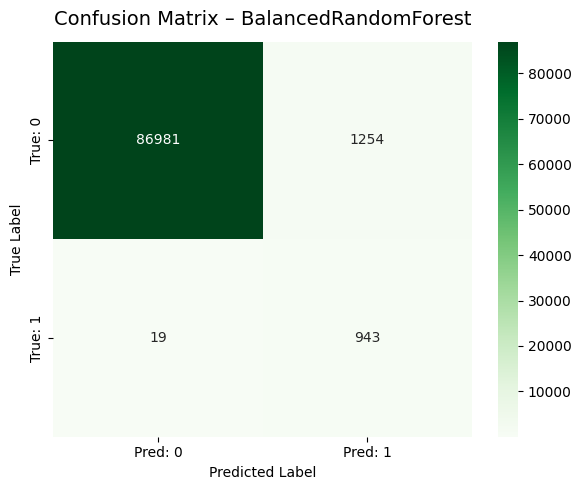

True Negatives  (TN): 86981
False Positives (FP): 1254
False Negatives (FN): 19
True Positives  (TP): 943


In [32]:
cm= confusion_matrix(y_test, brf_opt_test_preds)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Pred: 0', 'Pred: 1'],
    yticklabels=['True: 0', 'True: 1'],
    ax=ax
)
ax.set_title('Confusion Matrix – BalancedRandomForest', fontsize=14, pad=12)
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

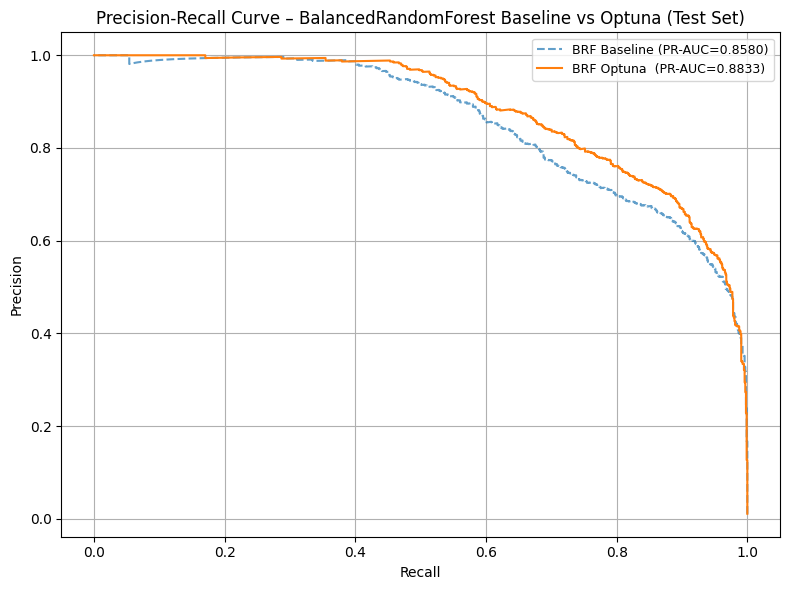

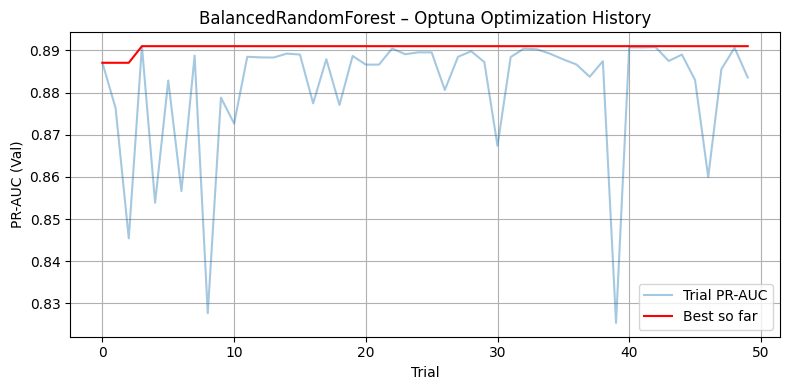

In [33]:
# Precision-Recall Curve – BalancedRandomForest Baseline vs Optuna
plt.figure(figsize=(8, 6))

prec_b, rec_b, _ = precision_recall_curve(y_test, brf_test_probs)
prec_o, rec_o, _ = precision_recall_curve(y_test, brf_opt_test_probs)
auc_b = average_precision_score(y_test, brf_test_probs)
auc_o = average_precision_score(y_test, brf_opt_test_probs)

plt.plot(rec_b, prec_b, linestyle="--", label=f"BRF Baseline (PR-AUC={auc_b:.4f})", alpha=0.7)
plt.plot(rec_o, prec_o, linestyle="-",  label=f"BRF Optuna  (PR-AUC={auc_o:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – BalancedRandomForest Baseline vs Optuna (Test Set)")
plt.legend(fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

# Optuna optimization history – BalancedRandomForest
plt.figure(figsize=(8, 4))
values = [t.value for t in brf_study.trials if t.value is not None]
best_so_far = pd.Series(values).cummax()
plt.plot(values, alpha=0.4, label="Trial PR-AUC")
plt.plot(best_so_far.values, color="red", label="Best so far")
plt.title("BalancedRandomForest – Optuna Optimization History")
plt.xlabel("Trial")
plt.ylabel("PR-AUC (Val)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 6. Feature Importance

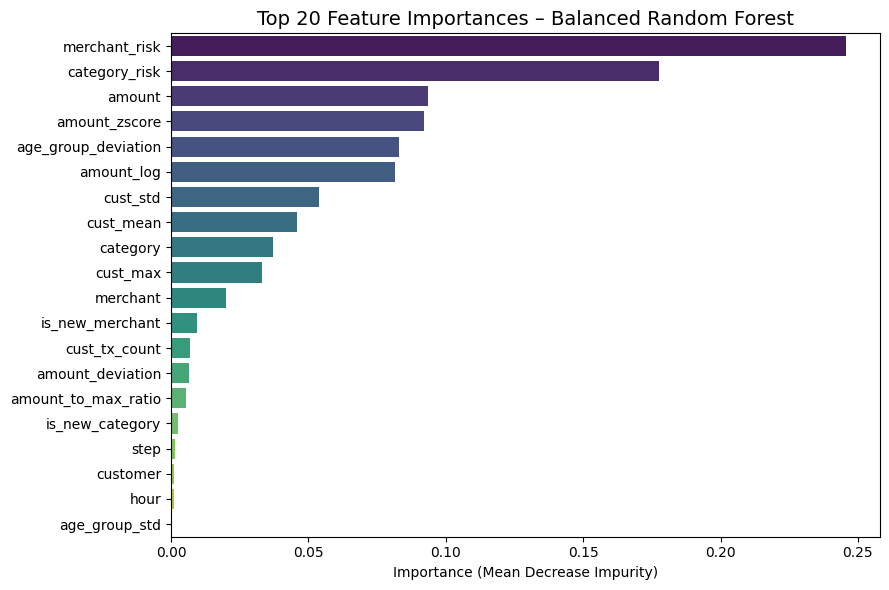


Top 20 features quan trọng nhất:
            feature  importance
      merchant_risk    0.245760
      category_risk    0.177492
             amount    0.093643
      amount_zscore    0.092008
age_group_deviation    0.082985
         amount_log    0.081606
           cust_std    0.053961
          cust_mean    0.045959
           category    0.037120
           cust_max    0.033041
           merchant    0.019966
    is_new_merchant    0.009615
      cust_tx_count    0.007070
   amount_deviation    0.006562
amount_to_max_ratio    0.005359
    is_new_category    0.002727
               step    0.001467
           customer    0.001162
               hour    0.000933
      age_group_std    0.000352


In [35]:
# Lấy feature importance và sắp xếp giảm dần
importance_df = pd.DataFrame({
    'feature':   feature_cols,
    'importance': brf_best.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

top_n = 20
top_df = importance_df.head(top_n)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(
    data=top_df, x='importance', y='feature',
    hue='feature', palette='viridis', legend=False, ax=ax
)
ax.set_title(f'Top {top_n} Feature Importances – Balanced Random Forest', fontsize=14)
ax.set_xlabel('Importance (Mean Decrease Impurity)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

print(f"\nTop {top_n} features quan trọng nhất:")
print(top_df.to_string(index=False))

## 7. Lưu mô hình

In [9]:
MODEL_SAVE_PATH = os.path.join(DATA_PATH, '..', 'models', 'brf_model.pkl')
os.makedirs(os.path.dirname(MODEL_SAVE_PATH), exist_ok=True)
joblib.dump(brf, MODEL_SAVE_PATH)
print(f"Mô hình đã được lưu tại: {os.path.abspath(MODEL_SAVE_PATH)}")

Mô hình đã được lưu tại: D:\AI66A_group_10_Topic_7\src\data\models\brf_model.pkl
